# Customer Segmentation with PCA & k-Means

**Goal:** turn a long lifestyle survey (93 questions about music, movies, interests, personality, phobias and spending habits) into a handful of **interpretable customer profiles**, the kind of summary a marketing team can actually use.

**Pipeline**

1. **Preprocessing**: ordinal encoding of categorical answers + standardization
2. **Variance analysis**: why scaling matters before PCA
3. **Dimensionality reduction**: PCA from 93 features to 5 interpretable components
4. **Segmentation**: k-Means, with *k* selected through the silhouette score
5. **Validation**: internal (silhouette) and external (demographics not used for training)

**Stack:** Python · pandas · NumPy · scikit-learn · Matplotlib

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

RANDOM_SEED = 2024
DATA_PATH = Path('../data/survey_responses.csv')
IMG_DIR = Path('../images')
IMG_DIR.mkdir(exist_ok=True)

# ---- plot style --------------------------------------------------------------
INK, INK_2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.edgecolor': INK_2, 'axes.labelcolor': INK, 'text.color': INK,
    'xtick.color': INK_2, 'ytick.color': INK_2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'axes.axisbelow': True, 'legend.frameon': False,
})
# categorical palette (fixed order) - first three slots are colorblind-safe as a set
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948')
NEUTRAL = '#9a9994'

def save(fig, name):
    fig.savefig(IMG_DIR / f'{name}.png', facecolor='white')

## 2. Data

The data comes from the [Young People Survey](https://www.kaggle.com/datasets/miroslavsabo/young-people-survey): young respondents rated their preferences on a 1–5 scale. This analysis uses 506 respondents and 93 behavioural questions, grouped into 7 themes. Demographic columns (gender, age, home town…) are **kept out of the model** and only used afterwards to validate the segments.

In [2]:
FEATURE_GROUPS = {
    'Finance': ['Finances', 'Shopping centres', 'Branded clothing', 'Entertainment spending',
                'Spending on looks', 'Spending on gadgets', 'Spending on healthy eating'],
    'Health': ['Alcohol'],
    'Interests': ['History', 'Psychology', 'Politics', 'Mathematics', 'Physics', 'PC',
                  'Economy Management', 'Chemistry', 'Reading', 'Foreign languages', 'Medicine',
                  'Law', 'Cars', 'Art exhibitions', 'Countryside, outdoors', 'Musical instruments',
                  'Writing', 'Passive sport', 'Gardening', 'Celebrities', 'Fun with friends',
                  'Adrenaline sports', 'Pets'],
    'Movies': ['Movies', 'Comedy', 'Romantic', 'Sci-fi', 'War', 'Fantasy/Fairy tales',
               'Documentary', 'Western', 'Action'],
    'Music': ['Slow songs or fast songs', 'Country', 'Classical music', 'Pop', 'Rock',
              'Metal or Hardrock', 'Punk', 'Alternative', 'Latino'],
    'Personality': ['Daily events', 'Prioritising workload', 'Writing notes', 'Thinking ahead',
                    'Final judgement', 'Reliability', 'Keeping promises', 'Funniness',
                    'Criminal damage', 'Decision making', 'Elections', 'Judgment calls',
                    'Hypochondria', 'Empathy', 'Giving', 'Health', 'Changing the past', 'Charity',
                    'Punctuality', 'Lying', 'New environment', 'Appearence and gestures',
                    'Achievements', 'Children', 'Assertiveness', 'Getting angry',
                    'Knowing the right people', 'Public speaking', 'Unpopularity',
                    'Life struggles', 'Happiness in life', 'Small - big dogs', 'Personality',
                    "Parents' advice", 'Internet usage'],
    'Phobias': ['Flying', 'Storm', 'Darkness', 'Heights', 'Spiders', 'Snakes', 'Rats', 'Ageing',
                'Dangerous dogs'],
}
DEMOGRAPHICS = ['Age', 'Height', 'Weight', 'Number of siblings', 'Gender', 'Hand',
                'Education', 'Only child', 'Home Town Type', 'Home Type']
FEATURES = [f for group in FEATURE_GROUPS.values() for f in group]

df = pd.read_csv(DATA_PATH, index_col='respondent_id')
X_raw = df[FEATURES]
demo = df[DEMOGRAPHICS]

print(f'Respondents: {len(df)} | behavioural features: {len(FEATURES)} | demographics: {len(DEMOGRAPHICS)}')
print('Missing values:', df.isna().sum().sum())
pd.Series({g: len(f) for g, f in FEATURE_GROUPS.items()}, name='# features').to_frame().T

Respondents: 506 | behavioural features: 93 | demographics: 10
Missing values: 0


,Finance,Health,Interests,Movies,Music,Personality,Phobias
# features,7,1,23,9,9,35,9


In [3]:
X_raw.head()

,Finances,Shopping centres,Branded clothing,Entertainment spending,Spending on looks,Spending on gadgets,Spending on healthy eating,Alcohol,History,Psychology,...,Internet usage,Flying,Storm,Darkness,Heights,Spiders,Snakes,Rats,Ageing,Dangerous dogs
respondent_id,,,,,,,,,,,,,,,,,,,,,
453,2,1,1,5,3,4,5,social drinker,3,4,...,few hours a day,1,1,2,1,2,1,1,2,1
199,4,5,4,3,4,4,3,social drinker,5,3,...,few hours a day,2,1,1,2,5,2,2,1,1
301,5,3,1,1,1,2,3,social drinker,5,3,...,few hours a day,3,2,2,2,2,3,2,1,2
41,1,1,1,1,5,1,4,social drinker,5,4,...,few hours a day,3,3,5,4,5,5,4,3,1
426,5,5,5,5,4,4,5,social drinker,3,5,...,few hours a day,5,3,1,5,1,5,1,5,1


## 3. Preprocessing

**Encoding.** Four answers are text categories, but each one has a natural order (how often you drink, how punctual you are, how often you lie, how long you stay online). **Ordinal encoding** keeps that order with a single integer column per feature. One-hot encoding would throw the ordering away and add columns for nothing.

**Scaling.** PCA and k-Means both work with variances and Euclidean distances, so features with a wider spread would dominate. A **StandardScaler** (zero mean, unit variance) gives every question the same weight.

In [4]:
ORDINAL_LEVELS = {
    'Alcohol':        ['never', 'social drinker', 'drink a lot'],
    'Punctuality':    ['late', 'on time', 'early'],
    'Lying':          ['never', 'only to avoid hurting someone', 'sometimes', 'everytime it suits me'],
    'Internet usage': ['less than an hour a day', 'few hours a day', 'most of the day'],
}
cat_cols = X_raw.select_dtypes(exclude='number').columns.tolist()
assert set(cat_cols) == set(ORDINAL_LEVELS), cat_cols

encoder = OrdinalEncoder(categories=[ORDINAL_LEVELS[c] for c in cat_cols])
X_enc = X_raw.copy()
X_enc[cat_cols] = encoder.fit_transform(X_raw[cat_cols]).astype(int)

scaler = StandardScaler()
X_std = pd.DataFrame(scaler.fit_transform(X_enc), index=X_enc.index, columns=X_enc.columns)

summary = pd.DataFrame({
    'mean (encoded)': X_enc.mean(), 'std (encoded)': X_enc.std(),
    'mean (scaled)': X_std.mean(), 'std (scaled)': X_std.std(),
}).round(3)
summary.loc[cat_cols + ['Finances', 'Spending on looks', 'Spiders']]

,mean (encoded),std (encoded),mean (scaled),std (scaled)
Alcohol,1.115,0.562,-0.0,1.001
Punctuality,1.040,0.788,-0.0,1.001
Lying,1.723,0.744,-0.0,1.001
Internet usage,0.970,0.524,0.0,1.001
Finances,3.085,1.156,-0.0,1.001
Spending on looks,3.125,1.180,0.0,1.001
Spiders,2.850,1.548,0.0,1.001


## 4. Why scaling matters: variance analysis

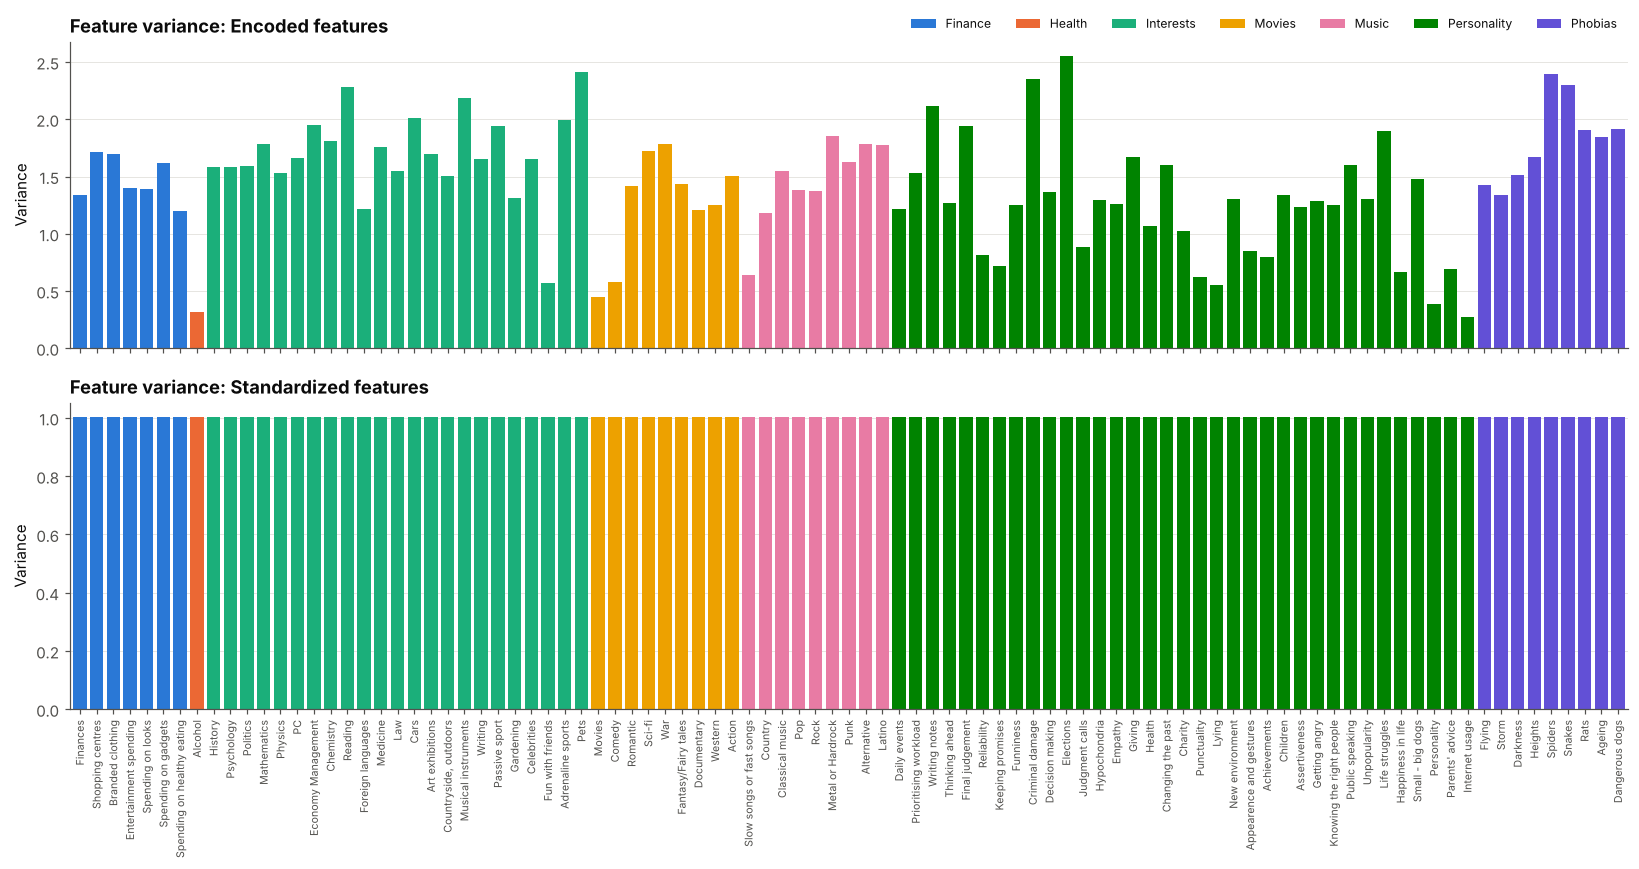

In [5]:
GROUP_COLORS = dict(zip(FEATURE_GROUPS, [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET]))
feat_colors = [GROUP_COLORS[g] for g, feats in FEATURE_GROUPS.items() for _ in feats]
group_legend = [Patch(facecolor=c, label=g) for g, c in GROUP_COLORS.items()]

fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
for ax, data, title in [(axes[0], X_enc, 'Encoded features'), (axes[1], X_std, 'Standardized features')]:
    ax.bar(range(len(FEATURES)), data.var().values, color=feat_colors, width=0.8)
    ax.set_title(f'Feature variance: {title}', loc='left')
    ax.set_ylabel('Variance')
    ax.grid(axis='x', visible=False)
axes[0].legend(handles=group_legend, ncol=7, loc='lower right', bbox_to_anchor=(1, 1.0), fontsize=8)
axes[1].set_xticks(range(len(FEATURES)), FEATURES, rotation=90, fontsize=7)
axes[1].set_xlim(-0.6, len(FEATURES) - 0.4)
fig.tight_layout()
save(fig, 'feature_variance')
plt.show()

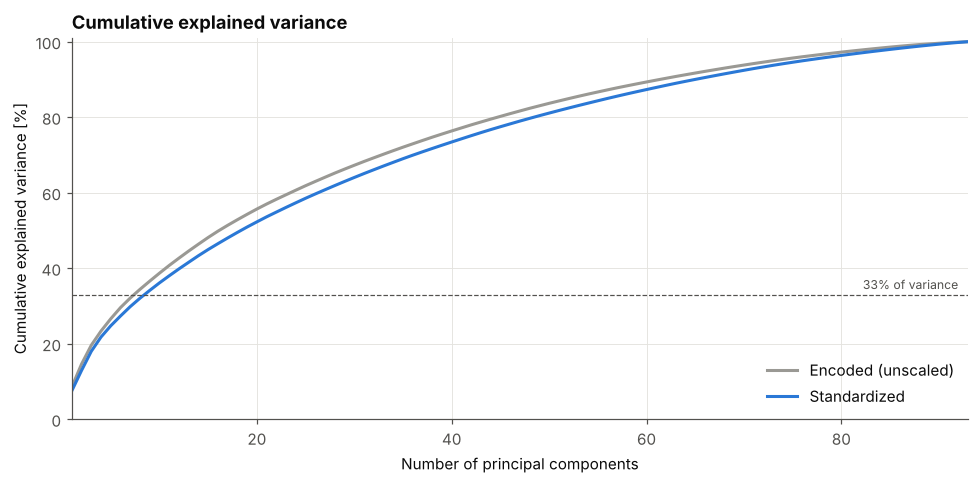

In [6]:
pca_enc = PCA().fit(X_enc)
pca_std = PCA().fit(X_std)
cum_enc = np.cumsum(pca_enc.explained_variance_ratio_)
cum_std = np.cumsum(pca_std.explained_variance_ratio_)
pcs = np.arange(1, len(FEATURES) + 1)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(pcs, cum_enc * 100, color=NEUTRAL, lw=2, label='Encoded (unscaled)')
ax.plot(pcs, cum_std * 100, color=BLUE, lw=2, label='Standardized')
ax.axhline(33, color=INK_2, lw=0.8, ls='--')
ax.text(92, 34.5, '33% of variance', ha='right', color=INK_2, fontsize=8)
ax.set(xlabel='Number of principal components', ylabel='Cumulative explained variance [%]',
       xlim=(1, len(FEATURES)), ylim=(0, 101))
ax.set_title('Cumulative explained variance', loc='left')
ax.legend(loc='lower right')
fig.tight_layout()
save(fig, 'cumulative_variance')
plt.show()

**Takeaways**
- Before scaling, variances differ a lot from question to question (the categorical codes have a very small spread), so an unscaled PCA would be driven by a few high-variance items. After standardization every feature has variance 1 and every theme contributes equally.
- The cumulative curve rises smoothly with **no sharp elbow**: as you'd expect from human survey data, information is spread across many questions. Still, the first components capture clear, interpretable patterns, which is what segmentation needs.

## 5. Dimensionality reduction with PCA

Number of components: *m* = min(*m′*, 5), where *m′* is the number of PCs needed to reach 33% of the variance. The cap at 5 keeps the components **interpretable**: each one has to become a named "lifestyle axis".

PCs needed for 33% of variance: m' = 9  ->  keeping m = 5
Variance preserved by 5 PCs: 24.7%


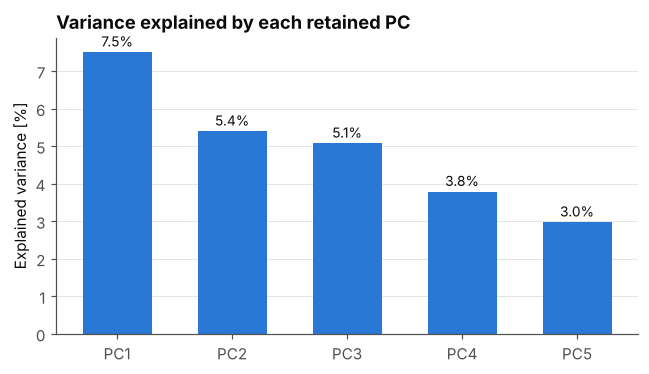

In [7]:
m_prime = int(np.argmax(cum_std >= 0.33) + 1)
m = min(m_prime, 5)

pca = PCA(n_components=m, random_state=RANDOM_SEED).fit(X_std)
scores = pca.transform(X_std)
print(f"PCs needed for 33% of variance: m' = {m_prime}  ->  keeping m = {m}")
print(f'Variance preserved by {m} PCs: {pca.explained_variance_ratio_.sum():.1%}')

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar([f'PC{i}' for i in range(1, m + 1)], pca.explained_variance_ratio_ * 100, color=BLUE, width=0.6)
for i, v in enumerate(pca.explained_variance_ratio_ * 100):
    ax.text(i, v + 0.15, f'{v:.1f}%', ha='center', fontsize=9, color=INK)
ax.set_ylabel('Explained variance [%]')
ax.set_title('Variance explained by each retained PC', loc='left')
ax.grid(axis='x', visible=False)
fig.tight_layout()
plt.show()

### Interpreting the components

For each PC, the loadings show how much each question contributes. Loadings beyond the threshold ±1/√n (red lines) are the ones that define the axis.

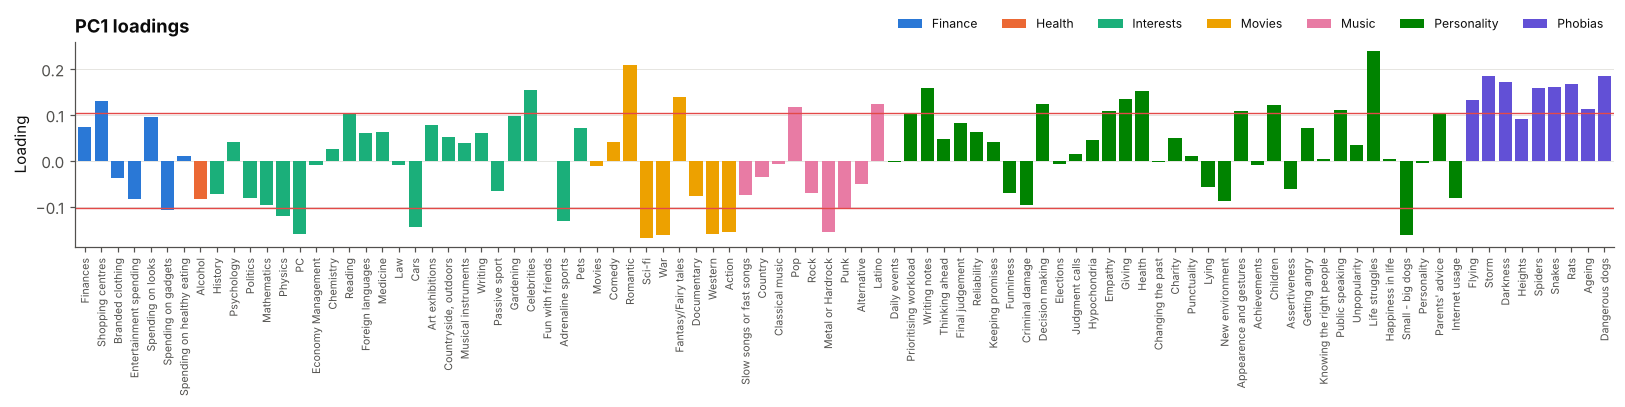

PC1 (+): Life struggles, Romantic, Storm, Dangerous dogs, Darkness, Rats, Snakes, Spiders, Writing notes, Celebrities
PC1 (-): Sci-fi, War, Small - big dogs, Western, PC, Action, Metal or Hardrock, Cars, Adrenaline sports, Physics


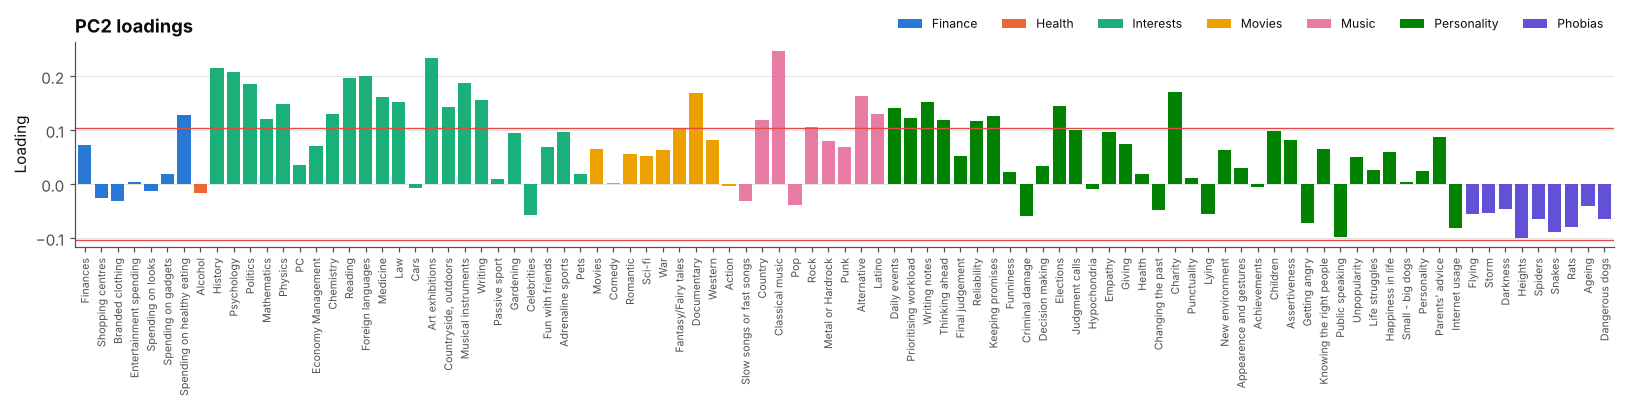

PC2 (+): Classical music, Art exhibitions, History, Psychology, Foreign languages, Reading, Musical instruments, Politics, Charity, Documentary
PC2 (-): 


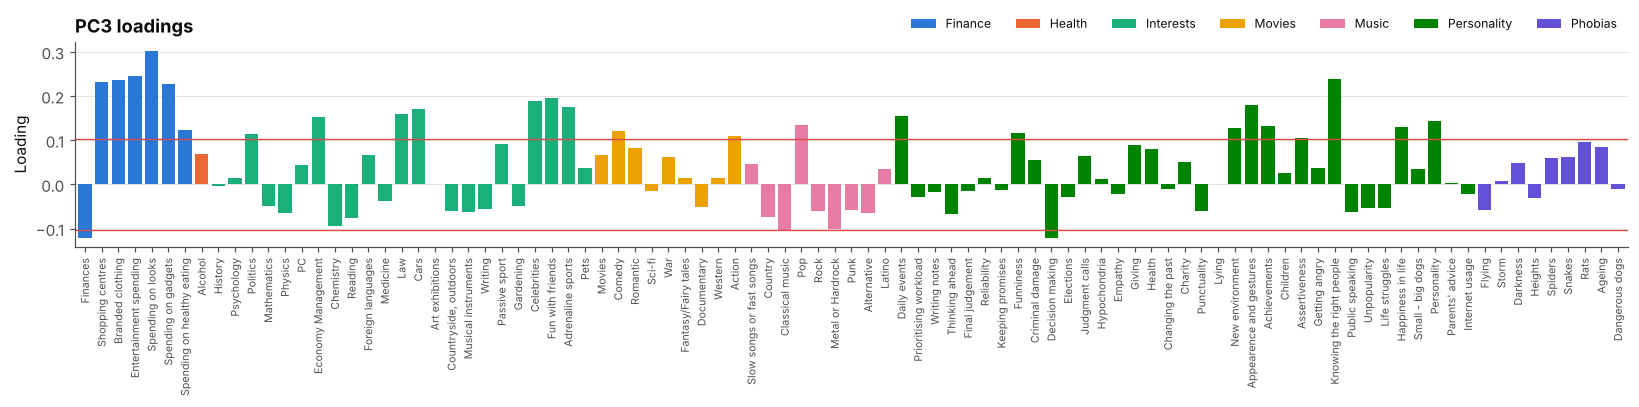

PC3 (+): Spending on looks, Entertainment spending, Knowing the right people, Branded clothing, Shopping centres, Spending on gadgets, Fun with friends, Celebrities, Appearence and gestures, Adrenaline sports
PC3 (-): Decision making, Finances


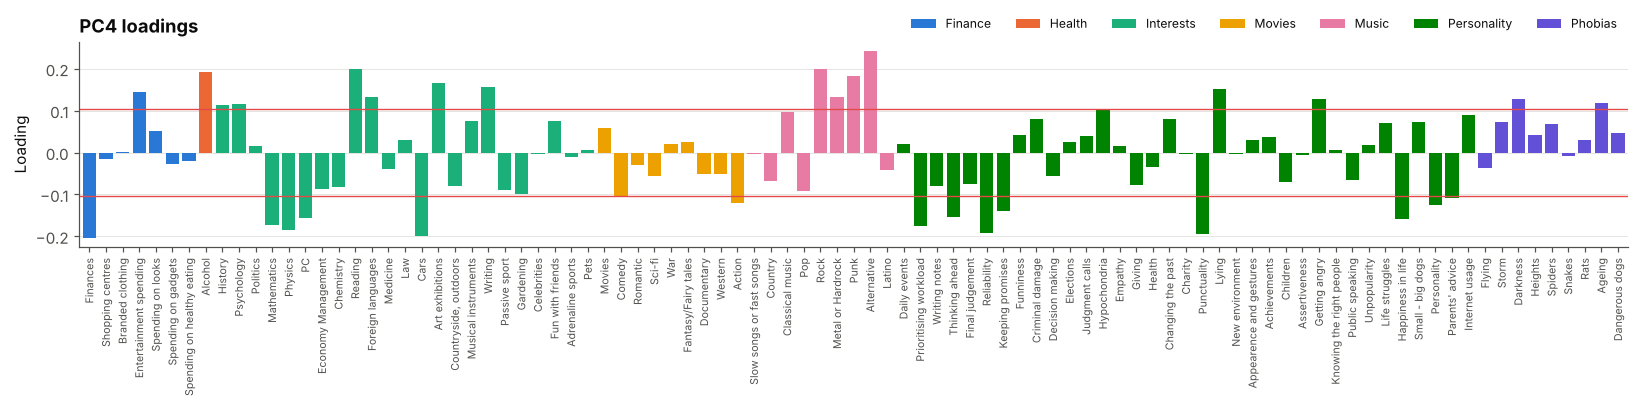

PC4 (+): Alternative, Reading, Rock, Alcohol, Punk, Art exhibitions, Writing, Lying, Entertainment spending, Foreign languages
PC4 (-): Finances, Cars, Punctuality, Reliability, Physics, Prioritising workload, Mathematics, Happiness in life, PC, Thinking ahead


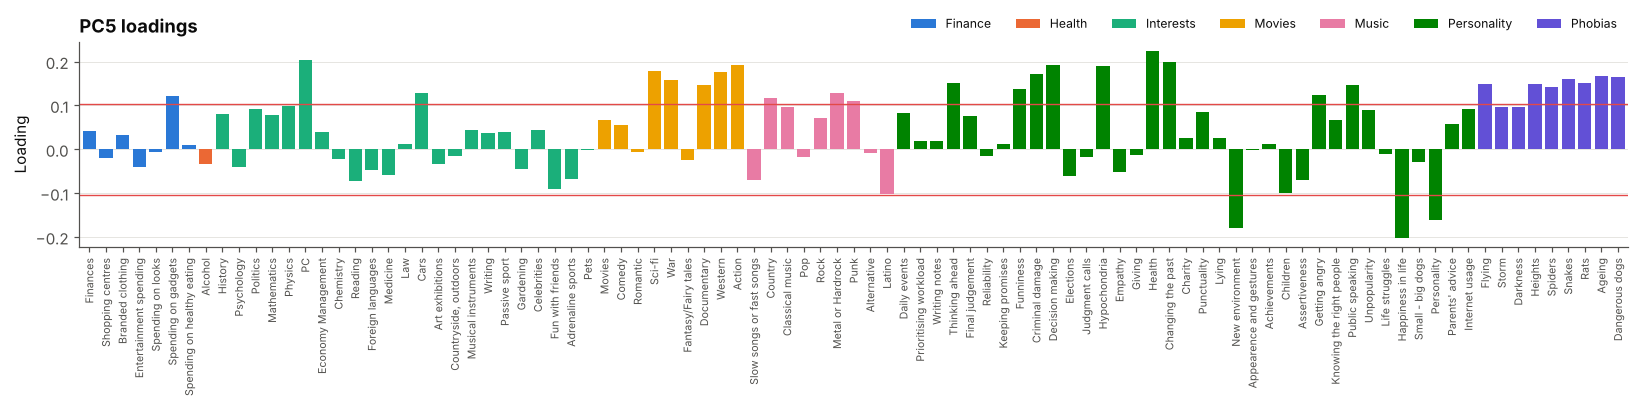

PC5 (+): Health, PC, Changing the past, Decision making, Action, Hypochondria, Sci-fi, Western, Criminal damage, Ageing
PC5 (-): Happiness in life, New environment, Personality


In [8]:
threshold = np.sqrt(1 / len(FEATURES))
loadings = pd.DataFrame(pca.components_.T, index=FEATURES, columns=[f'PC{i}' for i in range(1, m + 1)])

for pc in loadings.columns:
    fig, ax = plt.subplots(figsize=(15, 3.8))
    ax.bar(range(len(FEATURES)), loadings[pc], color=feat_colors, width=0.8)
    for t in (threshold, -threshold):
        ax.axhline(t, color=RED, lw=0.9)
    ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=90, fontsize=7)
    ax.set_xlim(-0.6, len(FEATURES) - 0.4)
    ax.set_ylabel('Loading')
    ax.set_title(f'{pc} loadings', loc='left')
    ax.grid(axis='x', visible=False)
    ax.legend(handles=group_legend, ncol=7, fontsize=8, loc='lower right', bbox_to_anchor=(1, 1.0))
    fig.tight_layout()
    if pc == 'PC1':
        save(fig, 'pc1_loadings')
    plt.show()

    top_pos = loadings[pc][loadings[pc] >= threshold].sort_values(ascending=False)
    top_neg = loadings[pc][loadings[pc] <= -threshold].sort_values()
    print(f'{pc} (+): ' + ', '.join(top_pos.index[:10]))
    print(f'{pc} (-): ' + ', '.join(top_neg.index[:10]))

| PC | Name | Negative pole (−) | Positive pole (+) |
|---|---|---|---|
| **PC1** | **Action & Tech ↔ Emotional Sensitivity** | sci-fi, war, action and western movies, PC, cars, metal | romantic movies, phobias (storms, darkness, spiders…), crying when things go wrong |
| **PC2** | **Academic & Cultural engagement** | no loading crosses the threshold (weak pull from fears, public-speaking anxiety, heavy internet use) | classical music, art exhibitions, history, psychology, languages, reading, politics |
| **PC3** | **Prudent ↔ Image & Fun** | careful decision-making, saving money, thinking ahead | spending on looks, branded clothes, partying, shopping centres, celebrities |
| **PC4** | **Conventional ↔ Non-conformist** | saving, punctuality, reliability, maths & physics | alternative/rock/punk music, reading & writing, alcohol, lying |
| **PC5** | **Confident ↔ Worried** | happiness in life, adapting to new places, assertiveness | health worries, hypochondria, regrets about the past |

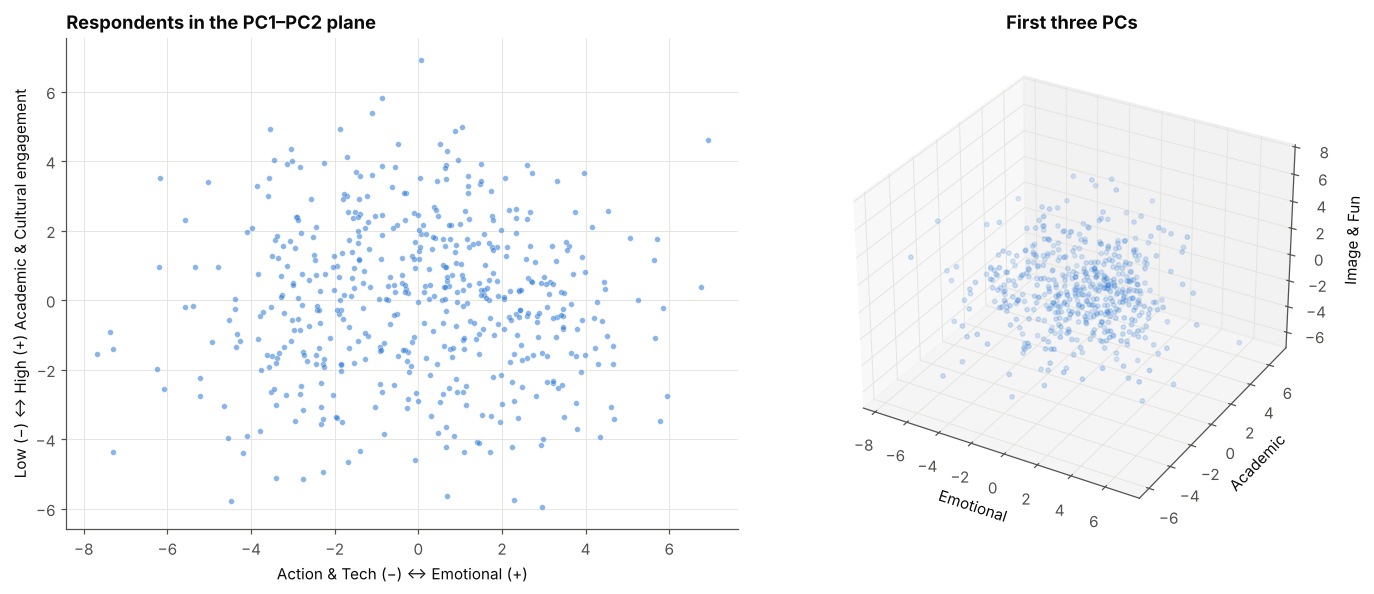

In [9]:
PC_NAMES = ['Action & Tech (−) ↔ Emotional (+)',
            'Low (−) ↔ High (+) Academic & Cultural engagement',
            'Prudent (−) ↔ Image & Fun (+)',
            'Conventional (−) ↔ Non-conformist (+)',
            'Confident (−) ↔ Worried (+)'][:m]
PC_SHORT = ['Emotional', 'Academic', 'Image & Fun', 'Non-conformist', 'Worried'][:m]

survey_pca = pd.DataFrame(scores, index=X_std.index, columns=PC_SHORT)

fig = plt.figure(figsize=(13, 5.5))
ax = fig.add_subplot(1, 2, 1)
ax.scatter(scores[:, 0], scores[:, 1], s=14, color=BLUE, alpha=0.55, edgecolors='white', linewidths=0.3)
ax.set(xlabel=PC_NAMES[0], ylabel=PC_NAMES[1])
ax.set_title('Respondents in the PC1–PC2 plane', loc='left')
ax3 = fig.add_subplot(1, 2, 2, projection='3d')
ax3.scatter(scores[:, 0], scores[:, 1], scores[:, 2], s=8, color=BLUE, alpha=0.5)
ax3.set_xlabel(PC_SHORT[0]); ax3.set_ylabel(PC_SHORT[1]); ax3.set_zlabel(PC_SHORT[2])
ax3.set_title('First three PCs')
fig.tight_layout()
plt.show()

## 6. Segmentation with k-Means

k-Means runs on the 5-dimensional PCA representation. *k* is chosen in {3, …, 10} by maximizing the **average silhouette score**.

3     0.1778
4     0.1683
5     0.1629
6     0.1609
7     0.1558
8     0.1427
9     0.1467
10    0.1481

Best k = 3


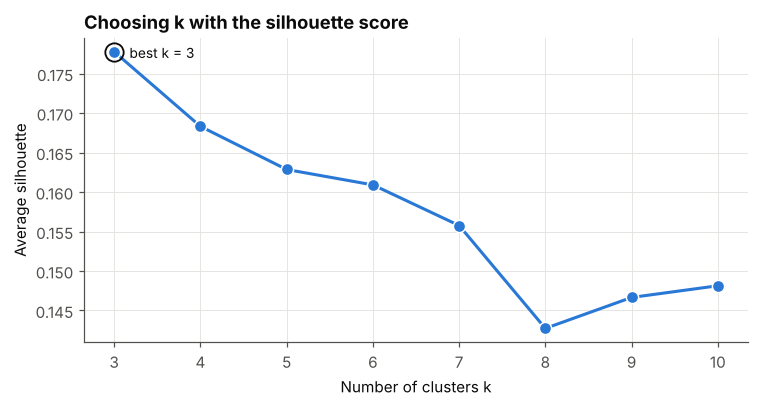

In [10]:
k_range = range(3, 11)
sil = {k: silhouette_score(scores, KMeans(n_clusters=k, random_state=RANDOM_SEED, n_init='auto')
                           .fit_predict(scores)) for k in k_range}
best_k = max(sil, key=sil.get)
print(pd.Series(sil, name='silhouette').round(4).to_string())
print(f'\nBest k = {best_k}')

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(list(sil), list(sil.values()), 'o-', color=BLUE, lw=2, ms=8, markeredgecolor='white')
ax.plot(best_k, sil[best_k], 'o', ms=12, mfc='none', mec=INK, mew=1.2)
ax.annotate(f'best k = {best_k}', (best_k, sil[best_k]), xytext=(10, -4), textcoords='offset points', fontsize=9)
ax.set(xlabel='Number of clusters k', ylabel='Average silhouette', xticks=list(k_range))
ax.set_title('Choosing k with the silhouette score', loc='left')
fig.tight_layout()
save(fig, 'silhouette_vs_k')
plt.show()

In [11]:
kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_SEED, n_init='auto').fit(scores)

# Give clusters a stable, meaningful order (k-Means label numbers are arbitrary):
# 0 = highest Academic score, 1 = highest Emotional score, 2 = lowest Emotional score
centers = kmeans.cluster_centers_
order = [int(np.argmax(centers[:, 1]))]
order.append(int(np.argmax(np.where(np.isin(range(best_k), order), -np.inf, centers[:, 0]))))
order += [c for c in np.argsort(centers[:, 0]) if c not in order]
remap = {old: new for new, old in enumerate(order)}
labels = np.array([remap[l] for l in kmeans.labels_])
centroids = centers[order]

SEGMENTS = ['The Model Student', 'The Social Enthusiast', 'The Digital & Action Profile'][:best_k]
SEG_COLORS = [BLUE, ORANGE, AQUA][:best_k]
silhouette_global = silhouette_score(scores, labels)

seg_sizes = pd.Series(labels).value_counts().sort_index()
pd.DataFrame({'segment': SEGMENTS, 'respondents': seg_sizes.values,
              'share': (seg_sizes.values / len(labels) * 100).round(1)})

,segment,respondents,share
0,The Model Student,158,31.2
1,The Social Enthusiast,196,38.7
2,The Digital & Action Profile,152,30.0


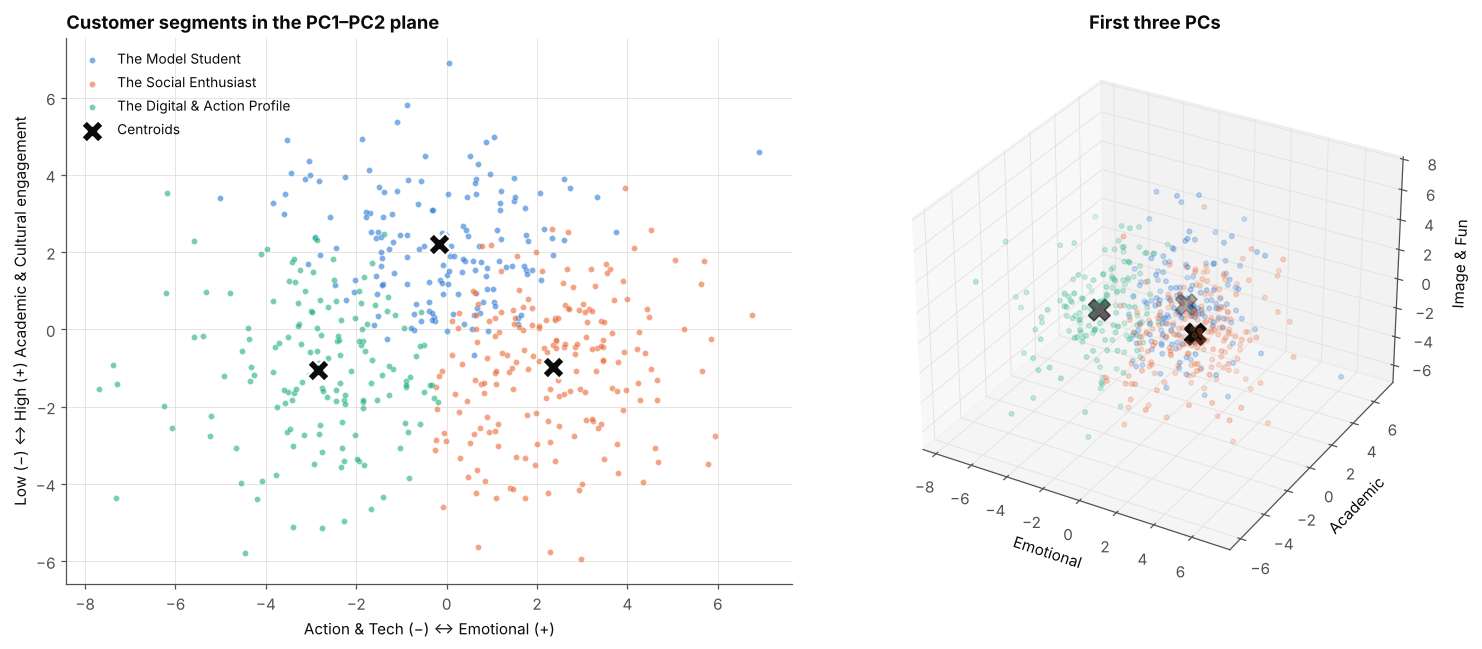

In [12]:
fig = plt.figure(figsize=(14, 6))
ax = fig.add_subplot(1, 2, 1)
for c, (name, col) in enumerate(zip(SEGMENTS, SEG_COLORS)):
    pts = scores[labels == c]
    ax.scatter(pts[:, 0], pts[:, 1], s=16, color=col, alpha=0.6, edgecolors='white', linewidths=0.3, label=name)
ax.scatter(centroids[:, 0], centroids[:, 1], marker='X', s=220, color=INK, edgecolors='white', linewidths=1.5, label='Centroids')
ax.set(xlabel=PC_NAMES[0], ylabel=PC_NAMES[1])
ax.set_title('Customer segments in the PC1–PC2 plane', loc='left')
ax.legend(loc='upper left', fontsize=9)

ax3 = fig.add_subplot(1, 2, 2, projection='3d')
for c, col in enumerate(SEG_COLORS):
    pts = scores[labels == c]
    ax3.scatter(pts[:, 0], pts[:, 1], pts[:, 2], s=9, color=col, alpha=0.55)
ax3.scatter(centroids[:, 0], centroids[:, 1], centroids[:, 2], marker='X', s=200, color=INK)
ax3.set_xlabel(PC_SHORT[0]); ax3.set_ylabel(PC_SHORT[1]); ax3.set_zlabel(PC_SHORT[2])
ax3.set_title('First three PCs')
fig.tight_layout()
save(fig, 'clusters')
plt.show()

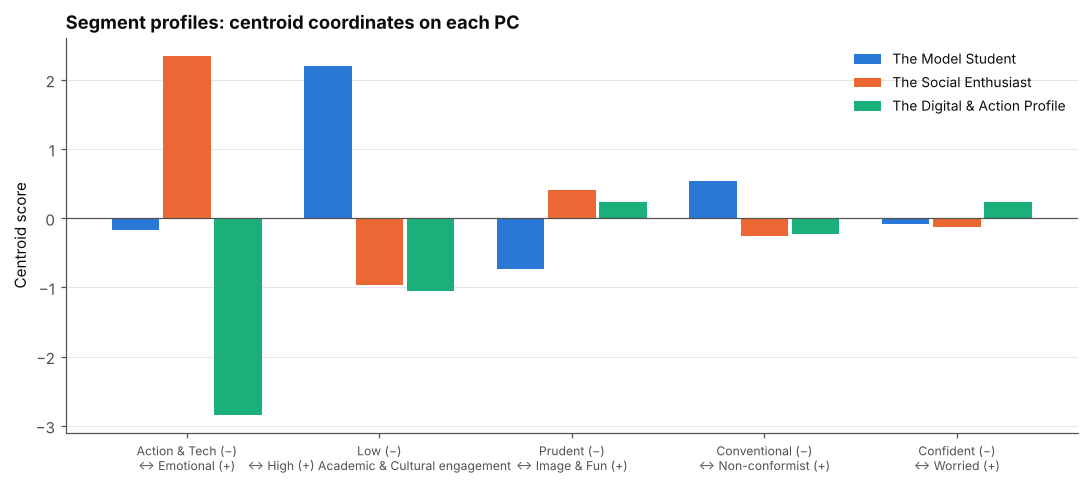

,Emotional,Academic,Image & Fun,Non-conformist,Worried
The Model Student,-0.18,2.20,-0.73,0.53,-0.08
The Social Enthusiast,2.35,-0.96,0.41,-0.25,-0.12
The Digital & Action Profile,-2.84,-1.05,0.23,-0.23,0.24


In [13]:
x = np.arange(m)
w = 0.8 / best_k
fig, ax = plt.subplots(figsize=(10, 4.5))
for c, (name, col) in enumerate(zip(SEGMENTS, SEG_COLORS)):
    ax.bar(x + (c - (best_k - 1) / 2) * w, centroids[c], width=w - 0.02, color=col, label=name)
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_xticks(x, [n.replace(' ↔ ', '\n↔ ') for n in PC_NAMES], fontsize=8)
ax.set_ylabel('Centroid score')
ax.set_title('Segment profiles: centroid coordinates on each PC', loc='left')
ax.grid(axis='x', visible=False)
ax.legend(fontsize=9, loc='upper right')
fig.tight_layout()
save(fig, 'segment_profiles')
plt.show()

pd.DataFrame(centroids, index=SEGMENTS, columns=PC_SHORT).round(2)

### The three segments

**The Model Student**: the steady, dutiful group. Average on emotional sensitivity and fears, but with by far the highest **Academic & Cultural** score: they read, visit exhibitions, study history and languages, keep their promises. Slightly on the *prudent* side of spending and a little more *non-conformist* (art, alternative music) than the others.

**The Social Enthusiast**: very high **Emotional** score and a positive **Image & Fun** score. They care about social life, entertainment and appearance, and are less academically oriented. The most clearly defined segment.

**The Digital & Action Profile**: strongly on the **Action & Tech** side (sci-fi, action movies, PCs, cars) and low on **Academic & Cultural** engagement. Not rigid or serious, since their Image & Fun score is slightly positive, but drawn to concrete activities and the digital world rather than emotional or social themes.

## 7. Validation

### External: do the segments line up with demographics?

Demographics were **not** used to build the clusters, so any strong relationship is an independent confirmation that the segments capture something real.

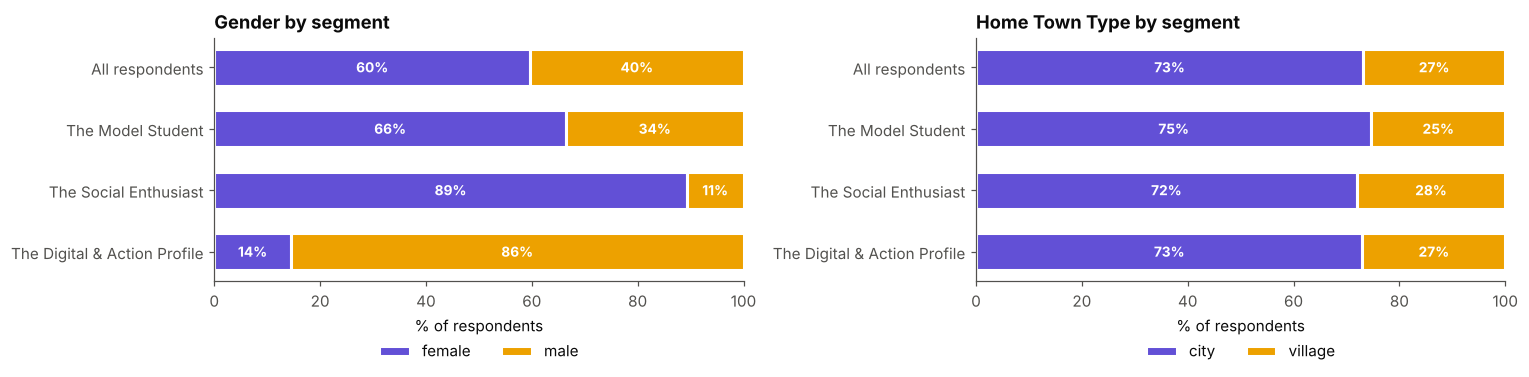

Gender       Home Town Type        
                             female  male           city village
All respondents                59.7  40.3           73.1    26.9
The Model Student              66.5  33.5           74.7    25.3
The Social Enthusiast          89.3  10.7           71.9    28.1
The Digital & Action Profile   14.5  85.5           73.0    27.0

In [14]:
def label_shares(col):
    tab = pd.crosstab(pd.Series(labels, index=demo.index).map(dict(enumerate(SEGMENTS))), demo[col], normalize='index')
    tab = tab.loc[SEGMENTS]
    overall = demo[col].value_counts(normalize=True).rename('All respondents')
    return pd.concat([overall.to_frame().T, tab])[overall.index] * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, col in zip(axes, ['Gender', 'Home Town Type']):
    shares = label_shares(col)
    left = np.zeros(len(shares))
    for val, color in zip(shares.columns, [VIOLET, YELLOW]):
        ax.barh(shares.index[::-1], shares[val][::-1], left=left[::-1], color=color,
                edgecolor='white', linewidth=2, label=val, height=0.6)
        for y, (l, v) in enumerate(zip(left[::-1], shares[val][::-1])):
            if v > 8:
                ax.text(l + v / 2, y, f'{v:.0f}%', ha='center', va='center', color='white', fontsize=9, fontweight='bold')
        left += shares[val].values
    ax.set_xlim(0, 100)
    ax.set_xlabel('% of respondents')
    ax.set_title(f'{col} by segment', loc='left')
    ax.grid(visible=False)
    ax.legend(ncol=2, loc='lower center', bbox_to_anchor=(0.5, -0.38))
fig.tight_layout()
save(fig, 'demographics_by_segment')
plt.show()

pd.concat({c: label_shares(c).round(1) for c in ['Gender', 'Home Town Type']}, axis=1)

- **Gender is a strong driver.** The full sample is about 60% female. *The Social Enthusiast* is overwhelmingly female, *The Digital & Action Profile* is overwhelmingly male, and *The Model Student* stays close to the overall mix. So the main Emotional ↔ Action & Tech axis (PC1) largely reflects gender-related differences in taste.
- **Home town type is neutral.** The city / village split is almost identical in every segment: the profiles cut across urban and rural backgrounds.

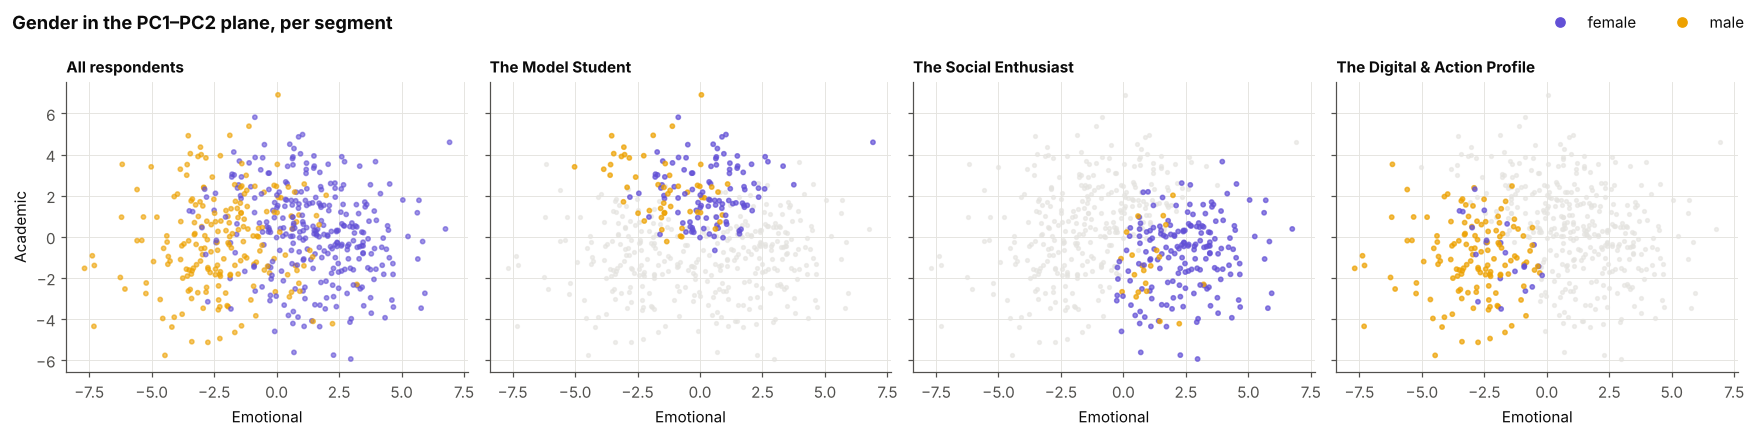

In [15]:
gender_colors = demo['Gender'].map({'female': VIOLET, 'male': YELLOW}).values
fig, axes = plt.subplots(1, best_k + 1, figsize=(16, 4), sharex=True, sharey=True)
axes[0].scatter(scores[:, 0], scores[:, 1], s=8, c=gender_colors, alpha=0.6)
axes[0].set_title('All respondents', loc='left', fontsize=10)
for c in range(best_k):
    mask = labels == c
    axes[c + 1].scatter(scores[~mask, 0], scores[~mask, 1], s=6, color=GRID, alpha=0.6)
    axes[c + 1].scatter(scores[mask, 0], scores[mask, 1], s=8, c=gender_colors[mask], alpha=0.7)
    axes[c + 1].set_title(SEGMENTS[c], loc='left', fontsize=10)
axes[0].set_ylabel(PC_SHORT[1])
for ax in axes:
    ax.set_xlabel(PC_SHORT[0])
fig.legend(handles=[Line2D([], [], marker='o', ls='', color=VIOLET, label='female'),
                    Line2D([], [], marker='o', ls='', color=YELLOW, label='male')],
           loc='upper right', ncol=2)
fig.suptitle('Gender in the PC1–PC2 plane, per segment', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
plt.show()

### Internal: how well separated are the segments?

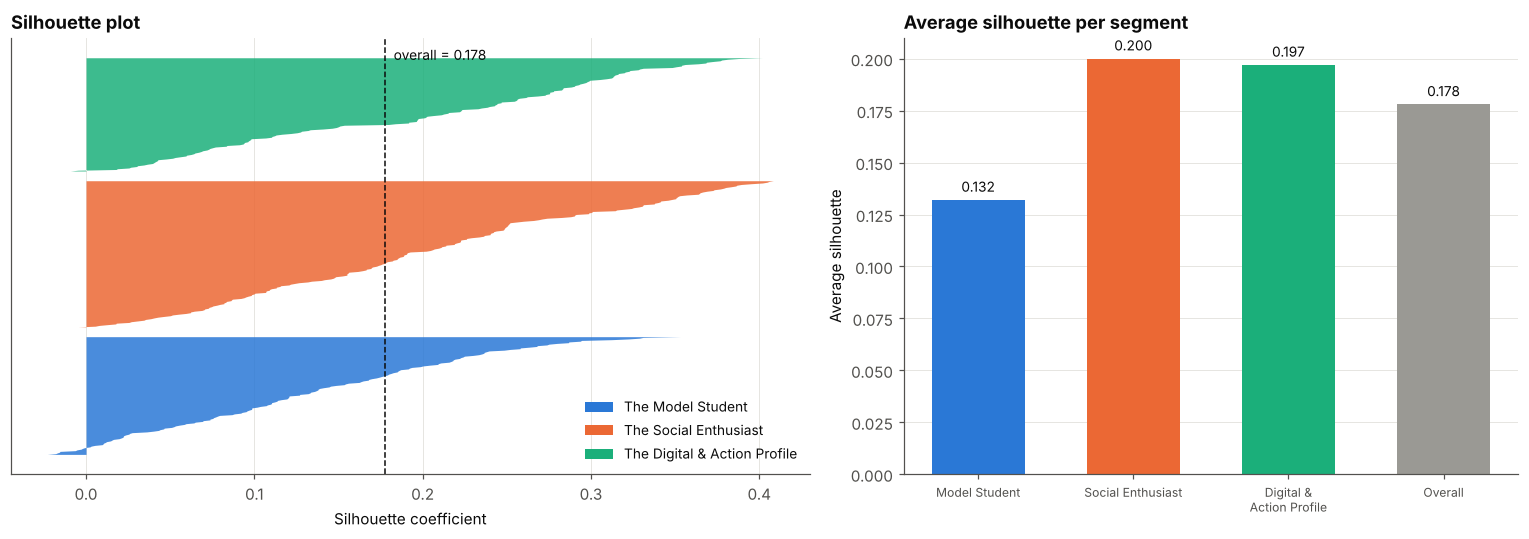

,Average silhouette
The Model Student,0.132
The Social Enthusiast,0.200
The Digital & Action Profile,0.197
Overall,0.178


In [16]:
sil_samples = silhouette_samples(scores, labels)
sil_table = pd.Series([sil_samples[labels == c].mean() for c in range(best_k)] + [silhouette_global],
                      index=SEGMENTS + ['Overall'], name='Average silhouette').round(3)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [1.3, 1]})
y0 = 0
for c, (name, col) in enumerate(zip(SEGMENTS, SEG_COLORS)):
    vals = np.sort(sil_samples[labels == c])
    ax1.fill_betweenx(np.arange(y0, y0 + len(vals)), 0, vals, color=col, alpha=0.85, lw=0)
    y0 += len(vals) + 12
ax1.axvline(silhouette_global, color=INK, ls='--', lw=1)
ax1.text(silhouette_global + 0.005, y0 + 2, f'overall = {silhouette_global:.3f}', fontsize=9, va='top')
ax1.set_yticks([])
ax1.legend(handles=[Patch(facecolor=c, label=n) for n, c in zip(SEGMENTS, SEG_COLORS)], loc='lower right', fontsize=9)
ax1.set_xlabel('Silhouette coefficient')
ax1.set_title('Silhouette plot', loc='left')
ax1.grid(axis='y', visible=False)

ax2.bar([n.replace('The ', '').replace(' & ', ' &\n') for n in sil_table.index], sil_table.values, color=SEG_COLORS + [NEUTRAL], width=0.6)
for i, v in enumerate(sil_table.values):
    ax2.text(i, v + 0.004, f'{v:.3f}', ha='center', fontsize=9)
ax2.set_ylabel('Average silhouette')
ax2.set_title('Average silhouette per segment', loc='left')
ax2.tick_params(axis='x', labelsize=8)
ax2.grid(axis='x', visible=False)
fig.tight_layout()
save(fig, 'silhouette')
plt.show()

sil_table.to_frame()

- Silhouette values are **positive but modest** (≈0.18 overall). That is typical of psychological survey data, where people don't fall into sharply separated groups.
- *The Social Enthusiast* and *The Digital & Action Profile* are the most cohesive segments: they sit at the two extremes of PC1.
- *The Model Student* has the lowest silhouette. It sits near the centre of the PC1 axis and borders both other segments, which fits its "balanced" profile.

## 8. Conclusions

- **93 survey questions → 5 interpretable lifestyle axes → 3 customer segments**, each with a clear and actionable description.
- The segments are **externally consistent**: gender, never seen by the model, splits sharply between *Social Enthusiasts* and *Digital & Action* profiles, while home town type is neutral.
- **Limitations:** the 5 PCs keep about 25% of the total variance, and cluster separation is moderate. The segments are best read as *tendencies*, not hard boundaries.
- **Possible extensions:** Gaussian Mixture Models for soft assignments, Factor Analysis or Varimax rotation for cleaner axes, and a classifier that assigns new respondents to a segment from a shortened questionnaire.